<a href="https://colab.research.google.com/github/KeshavFTW099/ArtificalAdvanced_NeuralNetworks/blob/main/099_ANN_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd

In [ ]:
text="deep learning is powerful"

In [ ]:
chars=sorted(set(text))
char2idx={u:i for i,u in enumerate(chars)}
idx2char=np.array(chars)

text_as_int = np.array([char2idx[c] for c in text])

In [ ]:
seq_length=10
exampels_per_epochs = len(text)//(seq_length+1)
char_dataset=tf.data.Dataset.from_tensor_slices(text_as_int)
sequences=char_dataset.batch(seq_length+1,drop_remainder=True)

def split_input_target(chunk):
  return chunk[:-1],chunk[1:]

dataset=sequences.map(split_input_target)

In [ ]:
vocab_size=len(chars)
embedding_dim=64
rnn_units=128
model=tf.keras.Sequential([
    tf.keras.layers.Embedding(vocab_size,embedding_dim),
    tf.keras.layers.GRU(rnn_units,return_sequences=True),
    tf.keras.layers.Dense(vocab_size)
])

In [ ]:
def loss(labels, logits):
  return tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)

model.compile(optimizer='adam', loss=loss)

In [ ]:
model.fit(dataset.batch(10),epochs=50)

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - loss: 2.7115
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - loss: 2.7017
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - loss: 2.6918
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - loss: 2.6818
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 2.6715
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 2.6609
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - loss: 2.6497
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 2.6379
Epoch 9/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 158ms/step - loss: 2.6253
Epoch 10/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - loss: 2.6117
Epoch 11/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - loss: 2.5970
Epoch 12/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - loss: 2.5810
Epoch 13/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - loss: 2.5635
Epoch 14/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - loss: 2.5443
Epoch 15/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - loss: 2.5231
Epoch 16/50
1/1 ━━━━━━━━━━━━━━━━

In [ ]:
def generate_text(model, start_string, num_generate=50):
    input_eval = [char2idx[s] for s in start_string]
    input_eval = tf.expand_dims(input_eval, 0)

    text_generated = []

    for i in range(num_generate):
        predictions = model(input_eval)
        predictions = tf.squeeze(predictions, 0)

        predicted_id = tf.random.categorical(
            predictions, num_samples=1
        )[-1, 0].numpy()

        input_eval = tf.expand_dims([predicted_id], 0)
        text_generated.append(idx2char[predicted_id])

    return start_string + ''.join(text_generated)

In [ ]:
print(generate_text(model,"deep "))

deep erfp piuolp ernuepewl sgedarn oauwgwelap fwepopp w


In [ ]:
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense,LSTM,Dropout,GRU,Bidirectional
from keras.optimizers import SGD
import math
from sklearn.metrics import mean_squared_error

In [ ]:
def plot_prediction(test,predicted):
  plt.plot(test,color='red',label='Real IBM Stock Price')
  plt.plot(predicted,color='blue',label='Predicted IBM Stock Price')
  plt.title('IBM Stock Price Prediction')
  plt.xlabel('Time')
  plt.ylabel('IBM Stock Price')
  plt.legend()
  plt.show()

In [ ]:
def return_rmse(test,predicted):
  rmse=math.sqrt(mean_squared_error(test,predicted))
  print("The root mean squared error is {} ".format(rmse))

In [ ]:
dataset=pd.read_csv('/content/IBM_2006-01-01_to_2018-01-01.csv', index_col='Date' , parse_dates=['Date'])
dataset.head()

,Open,High,Low,Close,Volume,Name
Date,,,,,,
2006-01-03,82.45,82.55,80.81,82.06,11715200,IBM
2006-01-04,82.20,82.50,81.33,81.95,9840600,IBM
2006-01-05,81.40,82.90,81.00,82.50,7213500,IBM
2006-01-06,83.95,85.03,83.41,84.95,8197400,IBM
2006-01-09,84.10,84.25,83.38,83.73,6858200,IBM


In [ ]:
dataset.tail()

,Open,High,Low,Close,Volume,Name
Date,,,,,,
2017-12-22,151.82,153.00,151.50,152.50,2990583,IBM
2017-12-26,152.51,153.86,152.50,152.83,2479017,IBM
2017-12-27,152.95,153.18,152.61,153.13,2149257,IBM
2017-12-28,153.20,154.12,153.20,154.04,2687624,IBM
2017-12-29,154.17,154.72,153.42,153.42,3327087,IBM


In [ ]:
training_set=dataset[:'2016'].iloc[:,1:2].values
test_set=dataset['2017':].iloc[:,1:2].values

/tmp/ipykernel_13459/237763761.py:3: UserWarning: Legend does not support handles for str instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  plt.legend('Training set (Before 2017)','Test set (2017 and beyond)')


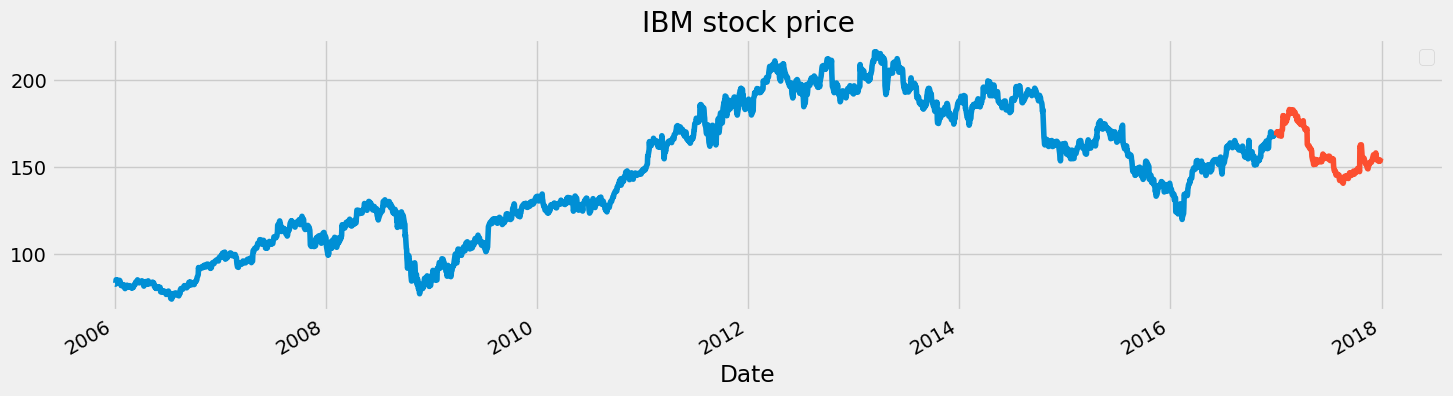

In [ ]:
dataset["High"][:'2016'].plot(figsize=(16,4),legend=True)
dataset["High"]['2017':].plot(figsize=(16,4),legend=True)
plt.legend('Training set (Before 2017)','Test set (2017 and beyond)')
plt.title('IBM stock price')
plt.show()

In [ ]:
sc=MinMaxScaler(feature_range=(0,1))
training_set_scaled=sc.fit_transform(training_set)

In [ ]:
X_train=[]
y_train=[]
for i in range(60,2769):
  X_train.append(training_set_scaled[i-60:i,0])
  y_train.append(training_set_scaled[i,0])
X_train,y_train=np.array(X_train),np.array(y_train)

In [ ]:
X_train=np.reshape(X_train,(X_train.shape[0],X_train.shape[1],1))

In [ ]:
regressor=Sequential()
regressor.add(LSTM(units=50,return_sequences=True,input_shape=(X_train.shape[1],1)))
regressor.add(Dropout(0.2))
regressor.add(LSTM(units=50,return_sequences=True))
regressor.add(Dropout(0.2))
regressor.add(LSTM(units=50,return_sequences=True))
regressor.add(Dropout(0.2))
regressor.add(LSTM(units=50))
regressor.add(Dropout(0.2))
regressor.add(Dense(units=1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
regressor.compile(optimizer='rmsprop',loss='mean_squared_error')
regressor.fit(X_train,y_train,epochs=15,batch_size=64)

Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - loss: 0.0351
Epoch 2/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0126
Epoch 3/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0099
Epoch 4/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0093
Epoch 5/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0081
Epoch 6/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0079
Epoch 7/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0070
Epoch 8/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0069
Epoch 9/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0057
Epoch 10/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0057
Epoch 11/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.0057
Epoch 12/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - loss: 0.0052
Epoch 13/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0052
Epoch 14/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0045
Epoch 15/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.0045


In [ ]:
dataset_total=pd.concat((dataset["High"][:'2016'],dataset["High"]['2017':]),axis=0)
inputs=dataset_total[len(dataset_total)-len(test_set)-60:].values
inputs=inputs.reshape(-1,1)
inputs=sc.transform(inputs)

In [ ]:
X_test=[]
for i in range(60,183):
  X_test.append(inputs[i-60:i,0])
X_test=np.array(X_test)
X_test=np.reshape(X_test,(X_test.shape[0],X_test.shape[1],1))
predicted_stock_price=regressor.predict(X_test)
predicted_stock_price=sc.inverse_transform(predicted_stock_price)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step
